# Does my fit score predict replies?

The job agent scores every resume 0-100 and acts on fixed thresholds: **build at 50, wait for review at 65, auto-apply at 80**. Those numbers were picked by hand. This notebook checks them against what actually happened to each application.

**Question:** among applications with a settled outcome, are higher scores more likely to get a recruiter reply, screen, interview or offer?

**What you practise here:** censoring (pending rows), confidence intervals on small samples, AUC, logistic regression and odds ratios, calibration, cross-validation, and power: how much data you need before trusting any of it.

**Data:** `../work/outcomes.csv`, written by `python -m jobagent outcomes add/set` (personal, git-ignored). If that file does not exist yet, the notebook makes a **synthetic demo log**, so every number below is fake until your own log replaces it. Cells marked **YOUR TURN** are for you to write: run, predict, then check.

In [1]:
import os, sys, datetime as dt
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

sys.path.insert(0, os.path.abspath(".."))
from jobagent import outcomes

LOG = "../work/outcomes.csv"
TODAY = dt.date(2026, 10, 14)   # pin the date so results are reproducible; change when you rerun
WINDOW = 30                     # days without a reply that count as "no"
rng = np.random.default_rng(7)

## 1. Load the log (or make the demo)

The demo's hidden truth: replies depend on **required coverage** and **freshness**, keywords do nothing, and the base rate is about 10%. Section 6 checks whether the analysis can recover that. Knowing the truth is the only way to test a method before trusting it on real data.

In [2]:
def demo_log(n=140):
    parts = pd.DataFrame({
        "required": rng.uniform(12, 30, n).round(1),
        "keywords": rng.uniform(5, 15, n).round(1),
        "preferred": rng.uniform(0, 5, n).round(1),
        "level": rng.choice([8, 11, 15], n, p=[.2, .3, .5]),
        "parse": rng.choice([7.5, 10], n, p=[.2, .8]),
        "freshness": rng.choice([2, 4, 7, 10], n),
        "signal": 7.0,
    })
    logit = -2.6 + 0.12 * (parts.required - 21) + 0.18 * (parts.freshness - 5.75)
    positive = rng.random(n) < 1 / (1 + np.exp(-logit))
    applied = [TODAY - dt.timedelta(days=int(d)) for d in rng.integers(1, 100, n)]
    df = parts.assign(app_id=[f"DEMO{i:03d}" for i in range(n)], applied=[a.isoformat() for a in applied],
                      family=rng.choice(["ds", "ai", "da"], n, p=[.4, .25, .35]),
                      source=rng.choice(["tsenta", "web"], n, p=[.7, .3]))
    df["score"] = parts.sum(axis=1).round(1)
    # Replies arrive 3-25 days after applying; one that would arrive after TODAY is not known yet.
    lag = rng.integers(3, 26, n)
    known = np.array([(TODAY - a).days >= l for a, l in zip(applied, lag)])
    df["outcome"] = np.where(positive & known, rng.choice(["recruiter_reply", "screen", "interview"], n),
                             np.where(~positive & (rng.random(n) < .35), "rejected", ""))
    return df

DEMO = not os.path.exists(LOG)
df = demo_log() if DEMO else pd.read_csv(LOG, dtype={"outcome": str}).fillna({"outcome": ""})
print(("DEMO DATA (synthetic)" if DEMO else "YOUR DATA"), "-", len(df), "applications")
df.head()

DEMO DATA (synthetic) - 140 applications


,required,keywords,preferred,level,parse,freshness,signal,app_id,applied,family,source,score,outcome
0,23.3,12.4,3.4,15,10.0,7,7.0,DEMO000,2026-09-06,ds,web,78.1,
1,28.1,10.8,1.9,15,7.5,7,7.0,DEMO001,2026-08-06,ai,tsenta,77.3,rejected
2,26.0,9.3,0.3,8,10.0,7,7.0,DEMO002,2026-07-26,da,web,67.6,
3,16.1,13.8,2.6,15,7.5,10,7.0,DEMO003,2026-07-25,ds,tsenta,72.0,
4,17.4,9.1,3.8,8,10.0,10,7.0,DEMO004,2026-07-11,da,web,65.3,


## 2. Label outcomes, and why pending is not "no"

`outcomes.label` gives 1 for a reply/screen/interview/offer and 0 for a rejection or silence after `WINDOW` days. Anything newer with no reply is **pending** and left out.

If pending rows counted as 0, last week's applications would look like failures just because employers haven't answered yet. Survival analysis calls this **right-censoring**.

In [3]:
df["y"] = [outcomes.label(r, TODAY, WINDOW) for r in df.astype(str).to_dict("records")]
settled = df[df.y.notna()].copy()
settled["y"] = settled.y.astype(int)
print(f"settled {len(settled)}, pending {df.y.isna().sum()}, positives {settled.y.sum()}")

wrong = df.assign(y=df.y.fillna(0))
print(f"positive rate if pending counted as 'no': {wrong.y.mean():.1%}  vs  settled only: {settled.y.mean():.1%}")

settled 121, pending 19, positives 16
positive rate if pending counted as 'no': 11.4%  vs  settled only: 13.2%


## 3. Base rate with an honest interval

With 10 positives, "8.1%" is not one number but a range. The Wilson interval behaves well when the rate is small, where the textbook p ± 1.96·SE can go below zero.

In [4]:
k, n = settled.y.sum(), len(settled)
lo, hi = outcomes.wilson(k, n)
print(f"base rate {k/n:.1%}  95% CI {lo:.1%} to {hi:.1%}")

base rate 13.2%  95% CI 8.3% to 20.4%


**YOUR TURN 1.** Without running anything: if you had 4 positives out of 50, would the interval be wider or narrower than the one above, and roughly how wide? Then compute it with `outcomes.wilson(4, 50)` and see how close your guess was.

In [5]:
# YOUR TURN 1


## 4. Does the rate rise with the score?

Here are the agent's own bands. If the score means something, the rate should go up from left to right. Look at the error bars before the bar heights.

,band,n,pos,rate,lo,hi
0,0-65,33,3,0.091,0.031,0.236
1,65-72,47,6,0.128,0.060,0.252
2,72-80,32,4,0.125,0.050,0.281
3,80-100,9,3,0.333,0.121,0.646


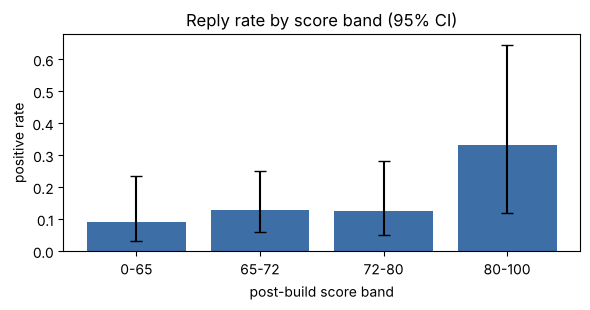

In [6]:
bands = [(0, 65), (65, 72), (72, 80), (80, 101)]
rows = []
for a, b in bands:
    s = settled[(settled.score >= a) & (settled.score < b)]
    lo, hi = outcomes.wilson(s.y.sum(), len(s))
    rows.append({"band": f"{a}-{min(b,100)}", "n": len(s), "pos": s.y.sum(),
                 "rate": s.y.mean() if len(s) else np.nan, "lo": lo, "hi": hi})
tab = pd.DataFrame(rows)
display(tab.round(3))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(tab.band, tab.rate, color="#3d6ea5")
ax.errorbar(tab.band, tab.rate, yerr=[tab.rate - tab.lo, tab.hi - tab.rate], fmt="none", color="k", capsize=4)
ax.set(xlabel="post-build score band", ylabel="positive rate", title="Reply rate by score band (95% CI)")
plt.tight_layout(); plt.show()

## 5. Ranking power: AUC, with a bootstrap interval

AUC is the chance that a random positive application scored higher than a random negative one. 0.5 is a coin flip; 0.7 is useful; 0.9 is unusual for this kind of problem.

The bootstrap resamples the applications with replacement 2,000 times and recomputes the AUC each time, which shows how much the number moves with this little data.

In [7]:
point = outcomes.auc(settled.score.tolist(), settled.y.tolist())
boot = []
for _ in range(2000):
    s = settled.sample(len(settled), replace=True, random_state=int(rng.integers(1e9)))
    a = outcomes.auc(s.score.tolist(), s.y.tolist())
    if a is not None:
        boot.append(a)
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"AUC {point:.3f}  bootstrap 95% CI {lo:.3f} to {hi:.3f}")
print("interval includes 0.5 -> cannot yet say the score beats a coin flip" if lo <= .5 else "interval is above 0.5")

AUC 0.595  bootstrap 95% CI 0.442 to 0.733
interval includes 0.5 -> cannot yet say the score beats a coin flip


## 6. Logistic regression: how much is 10 points worth?

The model is log-odds(positive) = a + b·score. **exp(10·b)** is the odds ratio for a 10-point higher score. For example, 1.8 means each 10 points multiplies the odds of a reply by 1.8.

The score is not a probability. A score of 80 does not mean an 80% chance, and the calibration plot shows what each score actually means.

odds ratio per +10 points: 1.92


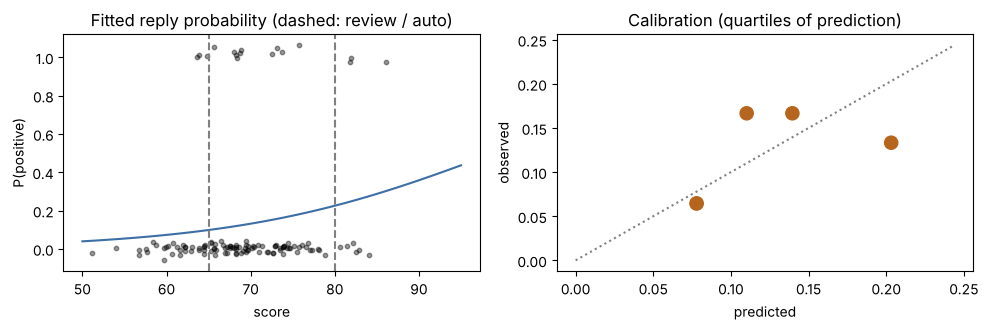

,pred,obs,n
p_hat,,,
"(0.0416, 0.0957]",0.078,0.065,31
"(0.0957, 0.12]",0.110,0.167,30
"(0.12, 0.162]",0.140,0.167,30
"(0.162, 0.302]",0.203,0.133,30


In [8]:
X, y = settled[["score"]].values, settled.y.values
m = LogisticRegression(C=1e6).fit(X, y)          # C=1e6: effectively no penalty, plain MLE
b = m.coef_[0][0]
print(f"odds ratio per +10 points: {np.exp(10*b):.2f}")

grid = np.linspace(50, 95, 100).reshape(-1, 1)
settled["p_hat"] = m.predict_proba(X)[:, 1]
cal = settled.groupby(pd.qcut(settled.p_hat, 4, duplicates="drop"), observed=True).agg(pred=("p_hat", "mean"), obs=("y", "mean"), n=("y", "size"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(grid, m.predict_proba(grid)[:, 1], color="#3d6ea5")
axes[0].scatter(settled.score, settled.y + rng.normal(0, .02, len(settled)), s=10, alpha=.4, color="k")
for t in (65, 80): axes[0].axvline(t, ls="--", color="grey")
axes[0].set(xlabel="score", ylabel="P(positive)", title="Fitted reply probability (dashed: review / auto)")
axes[1].plot([0, cal.pred.max()*1.2], [0, cal.pred.max()*1.2], ls=":", color="grey")
axes[1].scatter(cal.pred, cal.obs, s=cal.n*3, color="#b5651d")
axes[1].set(xlabel="predicted", ylabel="observed", title="Calibration (quartiles of prediction)")
plt.tight_layout(); plt.show()
display(cal.round(3))

## 7. Which parts of the score carry the signal?

The weights (30 required, 15 keywords, ...) were chosen by hand. A model on the parts asks which ones predict. Two cautions:

- With about 10 positives and 7 parts the model overfits easily. So it uses a penalty (L2, `C=0.5`) and is judged by **cross-validated** AUC, never by training AUC.
- Parts are on different scales, so they are standardised first and the coefficients become comparable.

total score only  cross-validated AUC 0.592 (+/- 0.193)
all parts         cross-validated AUC 0.452 (+/- 0.140)


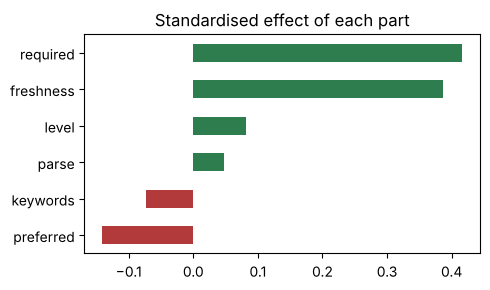

In [9]:
parts = [p for p in outcomes.PARTS if settled[p].astype(float).std() > 0]
Z = settled[parts].astype(float)
Z = (Z - Z.mean()) / Z.std()
cv = StratifiedKFold(5, shuffle=True, random_state=0)
for name, cols in [("total score only", ["score"]), ("all parts", parts)]:
    data = settled[["score"]].values if cols == ["score"] else Z.values
    aucs = cross_val_score(LogisticRegression(C=0.5), data, y, cv=cv, scoring="roc_auc")
    print(f"{name:17s} cross-validated AUC {aucs.mean():.3f} (+/- {aucs.std():.3f})")

coef = pd.Series(LogisticRegression(C=0.5).fit(Z.values, y).coef_[0], index=parts).sort_values()
coef.plot.barh(figsize=(5, 3), color=["#b23a3a" if c < 0 else "#2e7d4f" for c in coef], title="Standardised effect of each part")
plt.tight_layout(); plt.show()

**YOUR TURN 2.** In the demo, `keywords` has no real effect. Does its bar come out near zero? Rerun the notebook with `rng = np.random.default_rng(8)`: does its sign flip? Write one sentence on what that says about reading coefficients from about 140 rows.

In [10]:
# YOUR TURN 2


## 8. Choosing thresholds by cost, not by feel

A threshold is a business decision. Raising "auto" from 80 means fewer applications that don't need your review, but it also means missing replies. Below, every application above a cut-off counts as sent. The table shows how many you send and how many replies you keep.

Measured in the blueprint: about **37k tokens per resume**. Put your own value on an interview.

In [11]:
rows = []
for t in range(50, 91, 5):
    sent = settled[settled.score >= t]
    rows.append({"threshold": t, "sent": len(sent), "replies": int(sent.y.sum()),
                 "share_of_all_replies": sent.y.sum() / max(1, settled.y.sum()),
                 "reply_rate": sent.y.mean() if len(sent) else np.nan,
                 "resumes_per_reply": len(sent) / sent.y.sum() if sent.y.sum() else np.nan})
display(pd.DataFrame(rows).round(2))

,threshold,sent,replies,share_of_all_replies,reply_rate,resumes_per_reply
0,50,121,16,1.00,0.13,7.56
1,55,119,16,1.00,0.13,7.44
2,60,110,16,1.00,0.15,6.88
3,65,88,13,0.81,0.15,6.77
4,70,48,7,0.44,0.15,6.86
5,75,21,4,0.25,0.19,5.25
6,80,9,3,0.19,0.33,3.00
7,85,1,1,0.06,1.00,1.00
8,90,0,0,0.00,NaN,NaN


**YOUR TURN 3.** Pick a cost per resume (tokens plus your 2 minutes of review) and a value per reply. Write a function `net(t)` that returns value × replies − cost × sent for threshold `t`, and find the best `t`. Then ask whether the answer is stable: rerun it on 3 bootstrap samples of `settled`.

In [12]:
# YOUR TURN 3


## 9. Power: how many outcomes before any of this is trustworthy?

The simulation assumes the true effect is the demo's: odds ×1.8 per 10 points, with a 10% base rate. For each sample size it simulates 400 job searches and counts how often a one-sided test finds the effect at the 5% level. A common target is 80%.

In [13]:
def power(n, sims=400, or10=1.8, base=.10):
    b = np.log(or10) / 10
    a = np.log(base / (1 - base))
    hits = 0
    for _ in range(sims):
        s = rng.normal(70, 7, n)
        yy = rng.random(n) < 1 / (1 + np.exp(-(a + b * (s - 70))))
        if yy.sum() < 2 or yy.sum() > n - 2:
            continue
        auc_ = outcomes.auc(s.tolist(), yy.astype(int).tolist())
        # normal approximation to the Mann-Whitney test under H0: AUC = 0.5
        n1, n0 = yy.sum(), n - yy.sum()
        se = np.sqrt((n1 + n0 + 1) / (12 * n1 * n0))
        hits += (auc_ - .5) / se > 1.645
    return hits / sims

for n in (50, 100, 200, 400):
    print(f"{n:4d} settled applications -> power {power(n):.0%}")

  50 settled applications -> power 24%
 100 settled applications -> power 35%
 200 settled applications -> power 54%


 400 settled applications -> power 80%


## What to take from this

- **Until the report says there's enough data, do not change the thresholds.** Log every application and outcome, and rerun this notebook every couple of weeks.
- With a 10% reply rate, it takes a few hundred settled applications to detect a moderate effect. That's not a reason to send spam. It's a reason to decide **in advance** what evidence would change the thresholds.
- In the meantime, the per-family and per-source counts (`python -m jobagent outcomes report`) are worth watching. If one family replies at twice the rate of another, that matters more than any threshold.

Write your findings as a results table in `agent/README.md`. That's what turns the job agent into a data science project.